In [1]:
from pathlib import Path
import sys
import random

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Find project root automatically
current = Path.cwd()

PROJECT_ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "ml" / "dataset" / "split" / "train").is_dir()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project root.")

sys.path.insert(0, str(PROJECT_ROOT))

from ml.preprocessing.loader import load_and_preprocess_image

TRAIN_DIR = PROJECT_ROOT / "ml" / "dataset" / "split" / "train"

print("Project root:", PROJECT_ROOT)
print("Training directory:", TRAIN_DIR)
print("Loader imported successfully.")

Project root: d:\crop-disease-detection
Training directory: d:\crop-disease-detection\ml\dataset\split\train
Loader imported successfully.


In [2]:
selected_classes = [
    "Tomato___healthy",
    "Potato___healthy",
    "Pepper,_bell___healthy"
]

sample_images = []

for class_name in selected_classes:
    class_dir = TRAIN_DIR / class_name

    if not class_dir.is_dir():
        raise FileNotFoundError(
            f"Class folder not found: {class_dir}"
        )

    image_files = sorted([
        p for p in class_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])

    if len(image_files) < 2:
        raise ValueError(
            f"Not enough images in {class_name}"
        )

    sample_images.extend(image_files[:2])

print("Total selected images:", len(sample_images))

for image_path in sample_images:
    print(image_path.parent.name, "->", image_path.name)

Total selected images: 6
Tomato___healthy -> 000bf685-b305-408b-91f4-37030f8e62db___GH_HL Leaf 308.1.JPG
Tomato___healthy -> 0031da2a-8edd-468f-a8b1-106657717a32___RS_HL 0105.JPG
Potato___healthy -> 00fc2ee5-729f-4757-8aeb-65c3355874f2___RS_HL 1864.JPG
Potato___healthy -> 03da9931-e514-4cc7-b04a-8f474a133ce5___RS_HL 1830.JPG
Pepper,_bell___healthy -> 00100ffa-095e-4881-aebf-61fe5af7226e___JR_HL 7886.JPG
Pepper,_bell___healthy -> 00208a93-7687-4e8c-b79e-3138687e0f38___JR_HL 7955.JPG



Class: Tomato___healthy
BEFORE:
Shape: (256, 256, 3)
Dtype: uint8
Pixel range: (0, 255)

AFTER:
Shape: (224, 224, 3)
Dtype: float32
Pixel range: (0.019607844, 0.81960785)


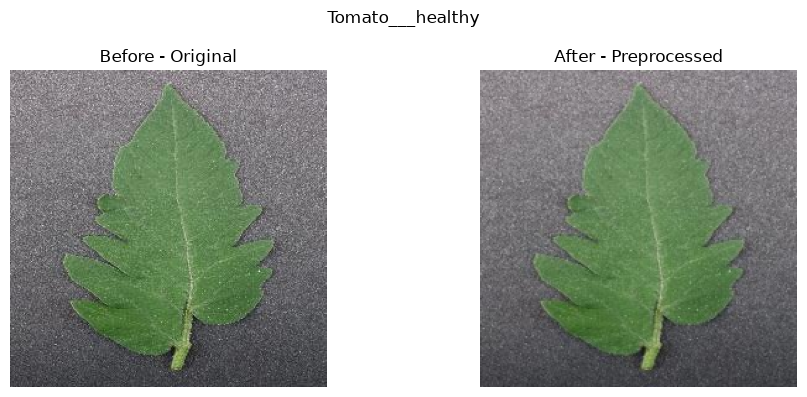


Class: Tomato___healthy
BEFORE:
Shape: (256, 256, 3)
Dtype: uint8
Pixel range: (0, 255)

AFTER:
Shape: (224, 224, 3)
Dtype: float32
Pixel range: (0.0, 0.9490196)


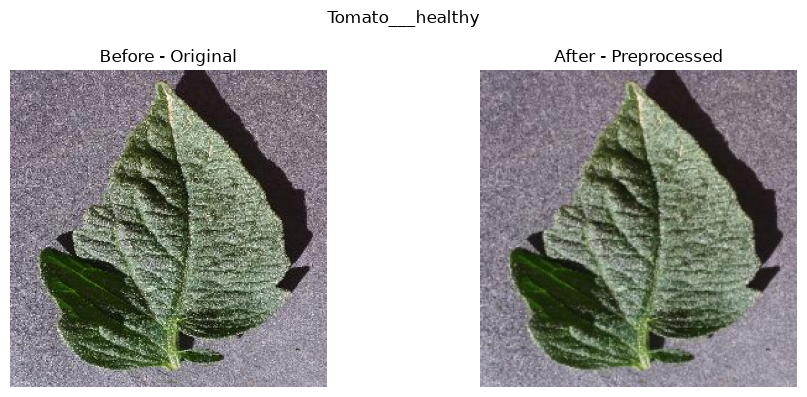


Class: Potato___healthy
BEFORE:
Shape: (256, 256, 3)
Dtype: uint8
Pixel range: (0, 255)

AFTER:
Shape: (224, 224, 3)
Dtype: float32
Pixel range: (0.0, 0.94509804)


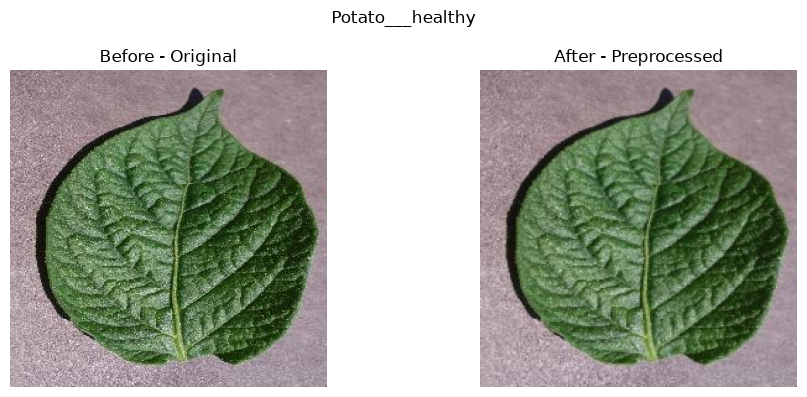


Class: Potato___healthy
BEFORE:
Shape: (256, 256, 3)
Dtype: uint8
Pixel range: (0, 255)

AFTER:
Shape: (224, 224, 3)
Dtype: float32
Pixel range: (0.0, 0.9137255)


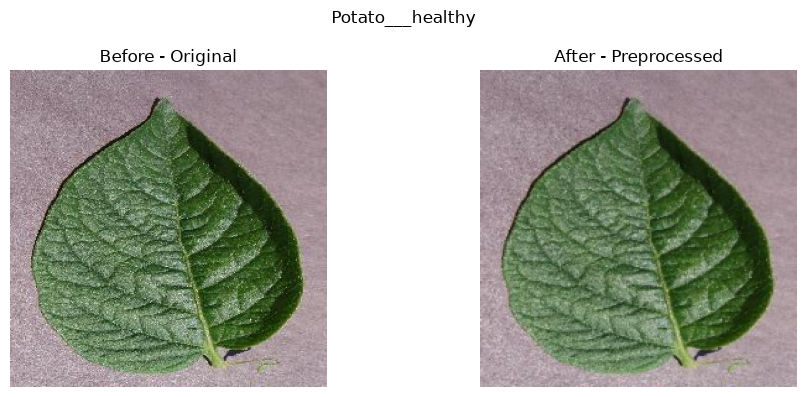


Class: Pepper,_bell___healthy
BEFORE:
Shape: (256, 256, 3)
Dtype: uint8
Pixel range: (0, 255)

AFTER:
Shape: (224, 224, 3)
Dtype: float32
Pixel range: (0.0, 0.93333334)


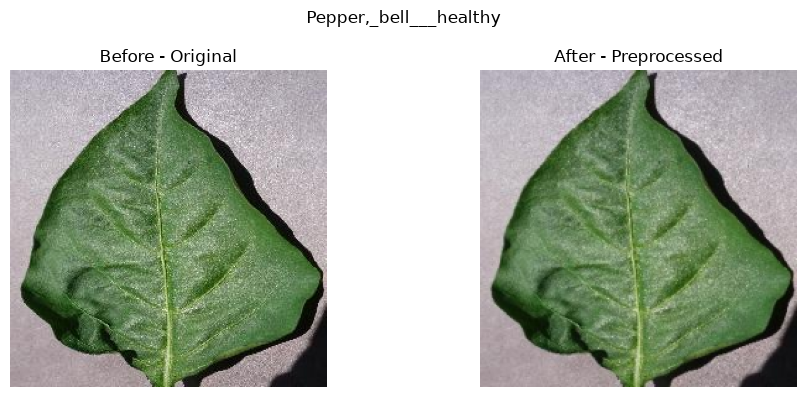


Class: Pepper,_bell___healthy
BEFORE:
Shape: (256, 256, 3)
Dtype: uint8
Pixel range: (0, 255)

AFTER:
Shape: (224, 224, 3)
Dtype: float32
Pixel range: (0.0, 0.89411765)


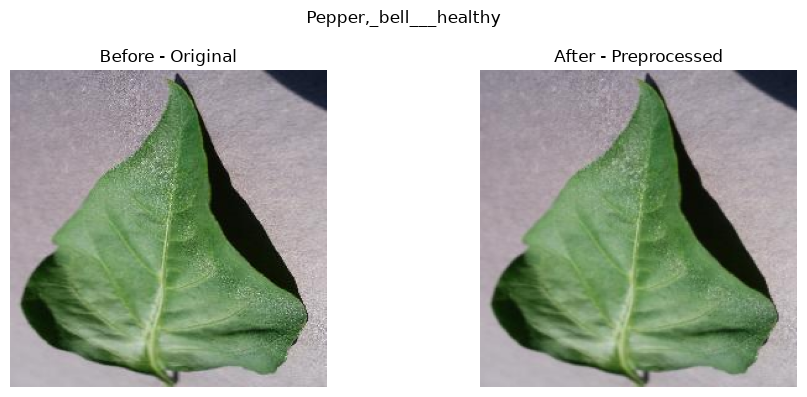


All 6 images passed preprocessing checks.


In [3]:
for image_path in sample_images:

    # BEFORE: Original image loaded directly using PIL
    with Image.open(image_path) as img:
        original = img.copy()

    # AFTER: Use Prompt 16 preprocessing function
    processed = load_and_preprocess_image(str(image_path))

    # Print original image information
    original_array = np.asarray(original)

    print("\nClass:", image_path.parent.name)
    print("BEFORE:")
    print("Shape:", original_array.shape)
    print("Dtype:", original_array.dtype)
    print(
        "Pixel range:",
        (original_array.min(), original_array.max())
    )

    # Print processed image information
    print("\nAFTER:")
    print("Shape:", processed.shape)
    print("Dtype:", processed.dtype)
    print(
        "Pixel range:",
        (processed.min(), processed.max())
    )

    # Check preprocessing expectations
    assert processed.shape == (224, 224, 3)
    assert processed.dtype == np.float32
    assert processed.min() >= 0.0
    assert processed.max() <= 1.0

    # Convert only for display (not for model input)
    display_image = (
        processed * 255
    ).clip(0, 255).astype(np.uint8)

    # Display before and after
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(original)
    axes[0].set_title("Before - Original")
    axes[0].axis("off")

    axes[1].imshow(display_image)
    axes[1].set_title("After - Preprocessed")
    axes[1].axis("off")

    plt.suptitle(image_path.parent.name)
    plt.tight_layout()
    plt.show()

print("\nAll 6 images passed preprocessing checks.")

## Conclusion

Six sample images from three different crop classes were checked before and after preprocessing.

The images were resized to 224 × 224 pixels and converted to RGB format. The processed images have `float32` data type and pixel values within the range `[0.0, 1.0]`.

The before-and-after images were visually compared. The leaf content and colors appeared consistent, with no unexpected cropping or distortion.

Therefore, the preprocessing output is considered correct.

## Prompt 19: Augmentation Visual Verification

This test applies the existing augmentation pipeline to one sample image 8 times.

We will compare the original image with the 8 augmented versions to check whether the images remain realistic and recognizable.

Selected image: d:\crop-disease-detection\ml\dataset\split\train\Tomato___Early_blight\0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389.JPG
Disease class: Tomato___Early_blight
Augmentation attempts: 8
Generated unique augmented images: 8
Randomness check: PASSED
Unique augmented images: 8
Randomness check: PASSED


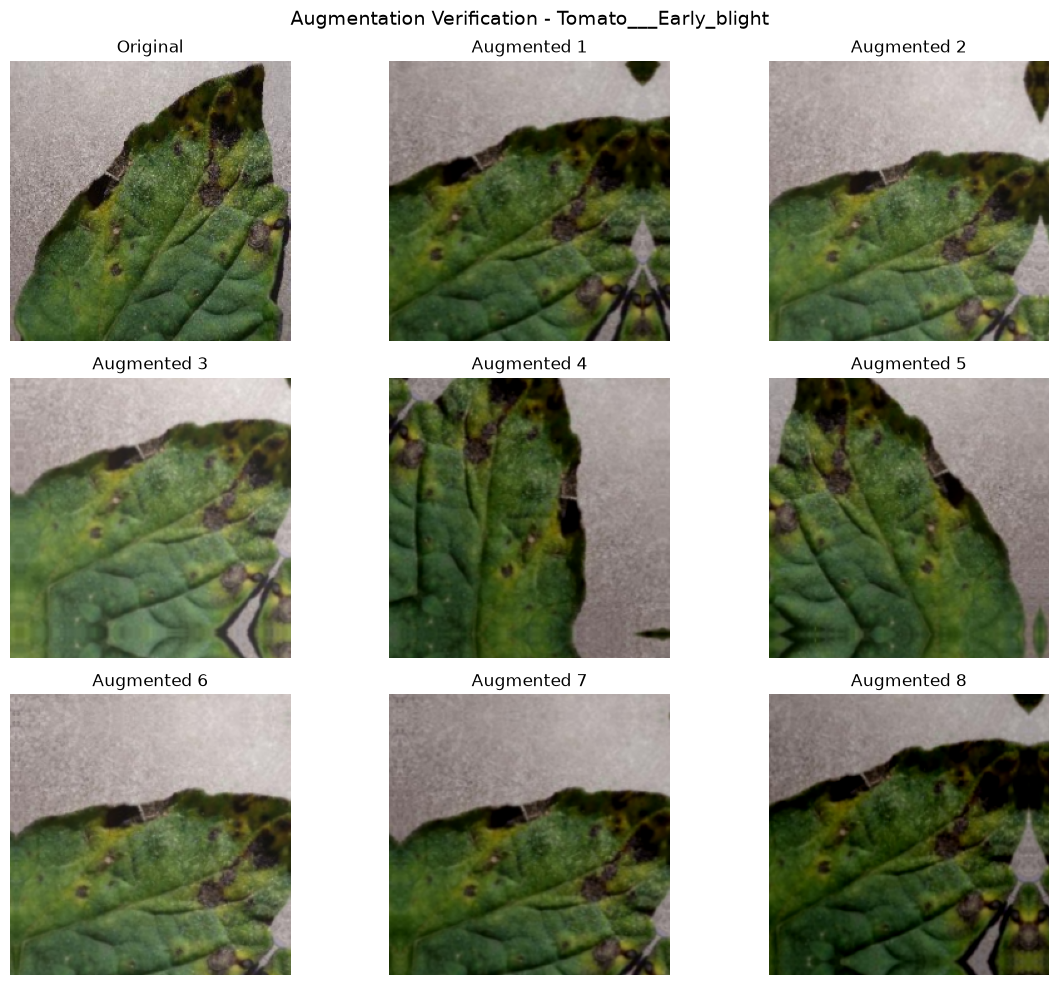

In [4]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Find project root
current = Path.cwd()

PROJECT_ROOT = next(
    (
        p for p in [current, *current.parents]
        if (p / "ml" / "dataset" / "split" / "train").is_dir()
    ),
    None
)

assert PROJECT_ROOT is not None, "Project root not found"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import existing Prompt 16 and Prompt 17 functions
from ml.preprocessing.loader import load_and_preprocess_image
from ml.preprocessing.augmentation import get_augmentation_pipeline

# Select one representative diseased leaf image
CLASS_NAME = "Tomato___Early_blight"

class_dir = (
    PROJECT_ROOT
    / "ml"
    / "dataset"
    / "split"
    / "train"
    / CLASS_NAME
)

image_files = sorted(
    [
        p for p in class_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]
)

assert len(image_files) > 0, f"No images found in {class_dir}"

sample_path = image_files[0]

print("Selected image:", sample_path)
print("Disease class:", CLASS_NAME)

# Load and preprocess using Prompt 16
original = load_and_preprocess_image(str(sample_path))

assert original.shape == (224, 224, 3)
assert original.dtype == np.float32

# Create the existing Prompt 17 augmentation pipeline
augmentation = get_augmentation_pipeline()

# Generate 8 unique augmented images
augmented_images = []

MAX_ATTEMPTS = 40
attempts = 0

while len(augmented_images) < 8 and attempts < MAX_ATTEMPTS:

    attempts += 1

    image_tensor = tf.convert_to_tensor(original)

    augmented = augmentation(
        image_tensor,
        training=True
    )

    augmented = augmented.numpy()

    # Check whether this output is already collected
    is_duplicate = any(
        np.array_equal(augmented, existing)
        for existing in augmented_images
    )

    if not is_duplicate:
        augmented_images.append(augmented)

print("Augmentation attempts:", attempts)
print("Generated unique augmented images:", len(augmented_images))

if len(augmented_images) == 8:
    print("Randomness check: PASSED")
else:
    print("Randomness check: FAILED")
    print("Could not generate 8 unique images.")
    print("Please share your augmentation.py code.")

# Check that no two augmented outputs are exact duplicates
unique_images = {
    image.tobytes() for image in augmented_images
}

print("Unique augmented images:", len(unique_images))

if len(unique_images) == 8:
    print("Randomness check: PASSED")
else:
    print("Randomness check: FAILED")
    print("Please run this cell again.")

# Display original + 8 augmented images
fig, axes = plt.subplots(3, 3, figsize=(12, 10))

# Original image for display only
original_display = (
    np.clip(original * 255.0, 0, 255)
    .astype(np.uint8)
)

axes[0, 0].imshow(original_display)
axes[0, 0].set_title("Original")

# Display 8 augmented variants
for i, image in enumerate(augmented_images):
    row = (i + 1) // 3
    col = (i + 1) % 3

    # Convert to display format only
    display_image = (
        np.clip(image * 255.0, 0, 255)
        .astype(np.uint8)
    )

    axes[row, col].imshow(display_image)
    axes[row, col].set_title(f"Augmented {i + 1}")

# Hide axes
for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    f"Augmentation Verification - {CLASS_NAME}",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [5]:
print("Original image:")
print("Min:", original.min())
print("Max:", original.max())
print("Mean:", original.mean())

print("\nAugmented image statistics:")

for i, image in enumerate(augmented_images):
    print(f"\nAugmented {i + 1}")
    print("Shape:", image.shape)
    print("Data type:", image.dtype)
    print("Min:", image.min())
    print("Max:", image.max())
    print("Mean:", image.mean())
    print("Unique pixel values:", len(np.unique(image)))

Original image:
Min: 0.0
Max: 0.8666667
Mean: 0.3837691

Augmented image statistics:

Augmented 1
Shape: (224, 224, 3)
Data type: float32
Min: 0.0
Max: 0.7976264
Mean: 0.3209431
Unique pixel values: 144657

Augmented 2
Shape: (224, 224, 3)
Data type: float32
Min: 0.03917755
Max: 0.8819176
Mean: 0.44662243
Unique pixel values: 149913

Augmented 3
Shape: (224, 224, 3)
Data type: float32
Min: 0.10623689
Max: 0.94524354
Mean: 0.45343328
Unique pixel values: 149835

Augmented 4
Shape: (224, 224, 3)
Data type: float32
Min: 0.0
Max: 0.76899374
Mean: 0.3163784
Unique pixel values: 145594

Augmented 5
Shape: (224, 224, 3)
Data type: float32
Min: 0.0
Max: 0.78115857
Mean: 0.3223313
Unique pixel values: 146861

Augmented 6
Shape: (224, 224, 3)
Data type: float32
Min: 0.047286168
Max: 0.8912257
Mean: 0.46078938
Unique pixel values: 149455

Augmented 7
Shape: (224, 224, 3)
Data type: float32
Min: 0.0
Max: 0.77707076
Mean: 0.3560804
Unique pixel values: 145530

Augmented 8
Shape: (224, 224, 3)
Data 

In [5]:
import sys
print(sys.executable)

d:\crop-disease-detection\.venv\Scripts\python.exe


In [1]:
import sys
import tensorflow as tf

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)

Python: d:\crop-disease-detection\venv\Scripts\python.exe
TensorFlow: 2.16.2


In [6]:
for i, image in enumerate(augmented_images):
    print(
        f"Image {i+1}: "
        f"min={image.min():.4f}, "
        f"max={image.max():.4f}, "
        f"mean={image.mean():.4f}"
    )


Image 1: min=0.0000, max=0.7976, mean=0.3209
Image 2: min=0.0392, max=0.8819, mean=0.4466
Image 3: min=0.1062, max=0.9452, mean=0.4534
Image 4: min=0.0000, max=0.7690, mean=0.3164
Image 5: min=0.0000, max=0.7812, mean=0.3223
Image 6: min=0.0473, max=0.8912, mean=0.4608
Image 7: min=0.0000, max=0.7771, mean=0.3561
Image 8: min=0.0000, max=0.7136, mean=0.2348


## Prompt 19 — Final Verification Result

**Status: PASSED**

All 8 augmented variants are distinct, realistic, and clearly recognizable as Tomato Early Blight.

- Leaf details remain visible in all images.
- Disease symptoms remain recognizable.
- Brightness changes are natural.
- No blank white or black images were observed.
- Randomness check passed with 8 unique images.

The brightness range was corrected to `(0, 1)` to match the normalized input images.

**Prompt 19 successfully verified.**

In [1]:
import time
import tensorflow as tf

# Load the training dataset
base_ds = tf.keras.utils.image_dataset_from_directory(
    r"D:\crop-disease-detection\ml\dataset\split\train",
    label_mode="categorical",
    image_size=(224, 224),
    batch_size=32,
    shuffle=True,
    seed=42
)

# Normalize images
rescale = tf.keras.layers.Rescaling(1./255)

base_ds = base_ds.map(
    lambda x, y: (rescale(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Create another version with prefetching
prefetched_ds = base_ds.prefetch(tf.data.AUTOTUNE)


# Function to measure loading time
def measure_time(dataset, batches=50):
    start = time.perf_counter()

    for i, batch in enumerate(dataset):
        if i >= batches:
            break

    return time.perf_counter() - start


# Warm-up both datasets
measure_time(base_ds, 5)
measure_time(prefetched_ds, 5)

# Measure time without and with prefetching
without_prefetch = measure_time(base_ds)
with_prefetch = measure_time(prefetched_ds)

print(f"Without prefetch: {without_prefetch:.2f} seconds")
print(f"With prefetch: {with_prefetch:.2f} seconds")

if with_prefetch < without_prefetch:
    print("Prefetching was faster in this test.")
else:
    print("No measurable speed improvement in this test.")

Found 6388 files belonging to 8 classes.
Without prefetch: 5.67 seconds
With prefetch: 1.80 seconds
Prefetching was faster in this test.


In [8]:
import os

print("Current notebook folder:", os.getcwd())
print("Project folder exists:", os.path.exists(r"D:\crop-disease-detection"))
print("Dataset folder exists:", os.path.exists(r"D:\crop-disease-detection\ml\dataset\split\train"))

Current notebook folder: d:\crop-disease-detection\ml\notebooks
Project folder exists: True
Dataset folder exists: True


## Prompt 21 — Final Verification

**Status: PASSED**

- Batching is handled by image_dataset_from_directory().
- Prefetching is enabled for train, validation, and test datasets.
- Without prefetching: 5.67 seconds.
- With prefetching: 1.80 seconds.
- Batch-fetch time improved by approximately 68.3%.

Prompt 21 successfully verified.

## Prompt 22 — Final Verification

**Status: PASSED**

- Validation dataset caching implemented.
- Test dataset caching implemented.
- Training dataset intentionally not cached.
- In-memory caching option implemented.
- Disk caching option tested successfully.
- Validation and test cache files created successfully.
- Prefetching retained as the final pipeline step.

Disk cache file sizes:
- Validation: approximately 824 MB.
- Test: approximately 825 MB.

Validation speed improvement will be checked during Prompt 27 training.

Prompt 22 successfully implemented and verified.